<a href="https://colab.research.google.com/github/dherreraal/object_oriented_programming/blob/main/Clase_11/11_POO_Strings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cadenas de Caracteres en Java: Clase String y Métodos
### Universidad Nacional de Colombia
#### **Profesor:** David Alberto Herrera Alvarez
#### **Curso:** Programación Orientada a Objetos
---


## Índice de Contenido
1. Introducción al Manejo de Texto: De Caracteres a Cadenas (`char` vs. `String`)
2. La Clase `String`: Creación, Representación en Memoria y el *String Constant Pool*
3. La Inmutabilidad de las Cadenas: Fundamentos y Consecuencias en POO
4. Comparación de Cadenas: Identidad de Referencia (`==`) vs. Igualdad de Contenido (`equals` y `compareTo`)
5. Métodos Esenciales de la Clase `String`:
   - 5.1 Inspección y Tamaño (`length`, `charAt`, `isEmpty`)
   - 5.2 Búsqueda y Posición (`indexOf`, `lastIndexOf`, `contains`, `startsWith`, `endsWith`)
   - 5.3 Extracción y Recorte (`substring`, `trim`, `strip`)
   - 5.4 Transformación y Reemplazo (`toLowerCase`, `toUpperCase`, `replace`)
   - 5.5 División de Texto (`split`) y Conversión a Caracteres (`toCharArray`)
6. Conversión entre Cadenas y Tipos Numéricos (Parsing con `Integer` y `Double`, `String.valueOf`)
7. Lectura e Interacción de Cadenas por Consola (`Scanner.next()` vs. `Scanner.nextLine()`)
8. Buenas Prácticas de Rendimiento y la Clase `StringBuilder`
9. Ejercicios Prácticos
   - Ejercicio 1: Validador y Normalizador de Nombres y Correos (`NormalizadorTexto.java`)
   - Ejercicio 2: Analizador Estadístico de Texto y Conteo de Vocales/Consonantes (`AnalizadorTexto.java`)
   - Ejercicio 3: Inversor de Texto y Verificador de Palíndromos Multipalabra (`VerificadorPalindromo.java`)
   - Ejercicio 4: Extractor y Parser de Registros Tabulares (`ParserRegistros.java`)
   - Ejercicio 5: Cifrador y Descifrador César Orientado a Objetos (`CifradorCesar.java`)
10. Bibliografía y Referencias
---


## 1. Introducción al Manejo de Texto: De Caracteres a Cadenas (`char` vs. `String`)

En el desarrollo de software moderno, la gran mayoría de la información con la que interactúan los seres humanos se presenta en forma de texto: nombres de usuarios, correos electrónicos, descripciones de productos, direcciones, transacciones y mensajes de comunicación en red.

Para manipular texto eficazmente en Java, es indispensable comprender la distinción conceptual y física entre un carácter individual y una secuencia de caracteres.

### 1.1 El Carácter: Elemento Mínimo de Información
Un **carácter** (`char`) es la unidad atómica indivisible empleada para representar letras, dígitos numéricos, signos de puntuación, símbolos matemáticos y caracteres de control (como saltos de línea o tabulaciones).

En el hardware de una computadora, los caracteres no se almacenan como formas gráficas, sino como **números enteros** asignados mediante un esquema de codificación estándar:
* **ASCII (American Standard Code for Information Interchange):** Define 128 caracteres en su versión estándar (7 bits) y 256 en su versión extendida (8 bits o 1 byte). Representa el alfabeto anglosajón básico, dígitos del 0 al 9 y símbolos elementales. Por ejemplo, la letra `'A'` mayúscula tiene el código numérico **65**, `'B'` es **66**, y el dígito `'0'` es **48**.
* **Unicode (UTF-16 en Java):** Diseñado para abarcar todos los sistemas de escritura del planeta (alfabetos latino, griego, cirílico, árabe, kanji, ideogramas chinos, emojis, etc.). En Java, el tipo primitivo `char` ocupa **16 bits (2 bytes)** sin signo, permitiendo representar directamente más de 65,000 caracteres base conocidos como *Code Points* (puntos de código con formato `\uXXXX`).

En el código fuente de Java:
* Un literal de tipo carácter se encierra **estrictamente entre comillas simples**: `'A'`, `'z'`, `'9'`, `'$'`.
* Las secuencias de escape permiten representar caracteres especiales:
  * `\n`: Salto de línea (*newline*).
  * `\t`: Tabulación horizontal.
  * `\'`: Comilla simple.
  * `\"`: Comilla doble.
  * `\\`: Barra invertida (*backslash*).
  * `\u0041`: Notación hexadecimal Unicode (representa a la letra `'A'`).

### 1.2 La Cadena (`String`): Una Secuencia Ordenada de Caracteres
Una **cadena de texto** es una secuencia ordenada de cero o más caracteres. En Java, las cadenas no son tipos primitivos: se modelan mediante la clase fundamental **`java.lang.String`**.

Un literal de cadena se encierra **siempre entre comillas dobles**:
```java
String saludo = "¡Hola, comunidad universitaria!";
String vacia = ""; // Cadena vacía de longitud 0
```

### 1.3 Comparación Estructural: `char` (Primitivo) vs. `String` (Objeto por Referencia)
La diferencia en cómo la Máquina Virtual de Java (JVM) administra la memoria para un `char` y un `String` es fundamental en la Programación Orientada a Objetos:

<div align="center">
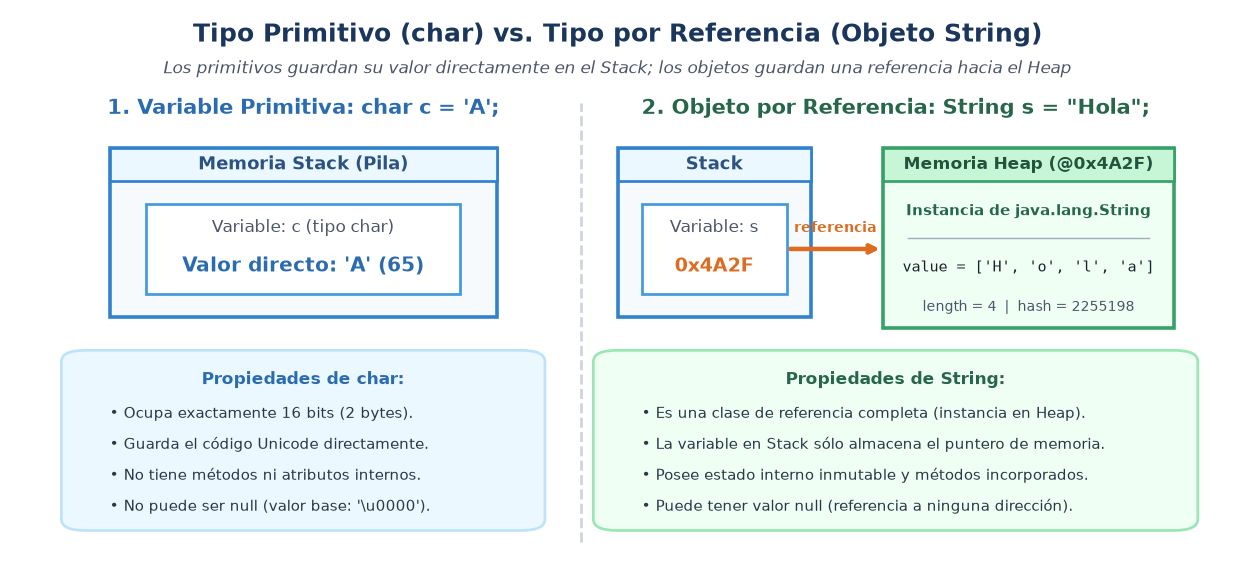
</div>

| Característica | Tipo Primitivo `char` | Tipo de Objeto `String` |
| :--- | :--- | :--- |
| **Categoría en Java** | Tipo de dato primitivo (palabra reservada en minúscula) | Clase de la biblioteca estándar (`java.lang.String`) |
| **Delimitador de sintaxis** | Comillas simples: `'a'` | Comillas dobles: `"a"` |
| **Almacenamiento en Memoria** | El valor numérico binario se almacena directamente en la variable (en el **Stack**) | La variable contiene una **referencia** (puntero a memoria) que apunta a un objeto en el **Heap** |
| **Espacio en Memoria** | Fijo y constante: exactamente 16 bits (2 bytes) | Dinámico: encabezado de objeto + longitud + arreglo interno de caracteres |
| **Estado y Comportamiento** | No posee métodos ni atributos internos | Posee estado encapsulado y más de 60 métodos (`length()`, `charAt()`, etc.) |
| **Valor por Defecto / Nulo** | `'\u0000'` (carácter nulo numérico 0) | Puede ser `null` (referencia que no apunta a ningún objeto en memoria) |


## 2. La Clase `String`: Creación, Representación en Memoria y el *String Constant Pool*

Dado que `String` es una clase, un desarrollador en Java puede instanciar cadenas de dos formas fundamentalmente distintas:

### 2.1 Creación por Literal vs. Creación con el Operador `new`
1. **Creación mediante Literal de Cadena:**
   ```java
   String s1 = "Java";
   String s2 = "Java";
   ```
2. **Creación mediante Constructor con `new`:**
   ```java
   String s3 = new String("Java");
   ```

Aunque las tres variables representan el mismo texto `"Java"`, la JVM las almacena de formas muy distintas en la memoria Heap.

### 2.2 El *String Constant Pool* (Mecanismo de Optimización)
En cualquier aplicación de software empresarial, ciertas cadenas de texto (como `"true"`, `"false"`, `"ID"`, códigos de estado HTTP o nombres de columnas) se repiten miles o millones de veces. Si cada literal creara un objeto independiente en el Heap, la memoria colapsaría rápidamente por duplicidad de datos.

Para resolver esto, la JVM implementa una región especial dentro de la memoria Heap denominada **String Constant Pool** (Piscina de Constantes de Cadena):
* Cuando el código declara un literal como `String s1 = "Java";`, la JVM revisa si `"Java"` ya existe en el *String Pool*.
* Si no existe, crea una nueva instancia de `"Java"` dentro del Pool y asigna su dirección a `s1`.
* Cuando otra línea declara `String s2 = "Java";`, la JVM detecta que `"Java"` ya reside en el Pool y **reutiliza exactamente la misma dirección de memoria**. Ambas variables `s1` y `s2` apuntan al mismo y único objeto físico en memoria.
* En cambio, cuando forzamos el uso del constructor `String s3 = new String("Java");`, la palabra clave `new` obliga a la JVM a reservar **un bloque de memoria Heap completamente nuevo e independiente**, fuera del Pool regular, ignorando cualquier optimización de reutilización.

<div align="center">
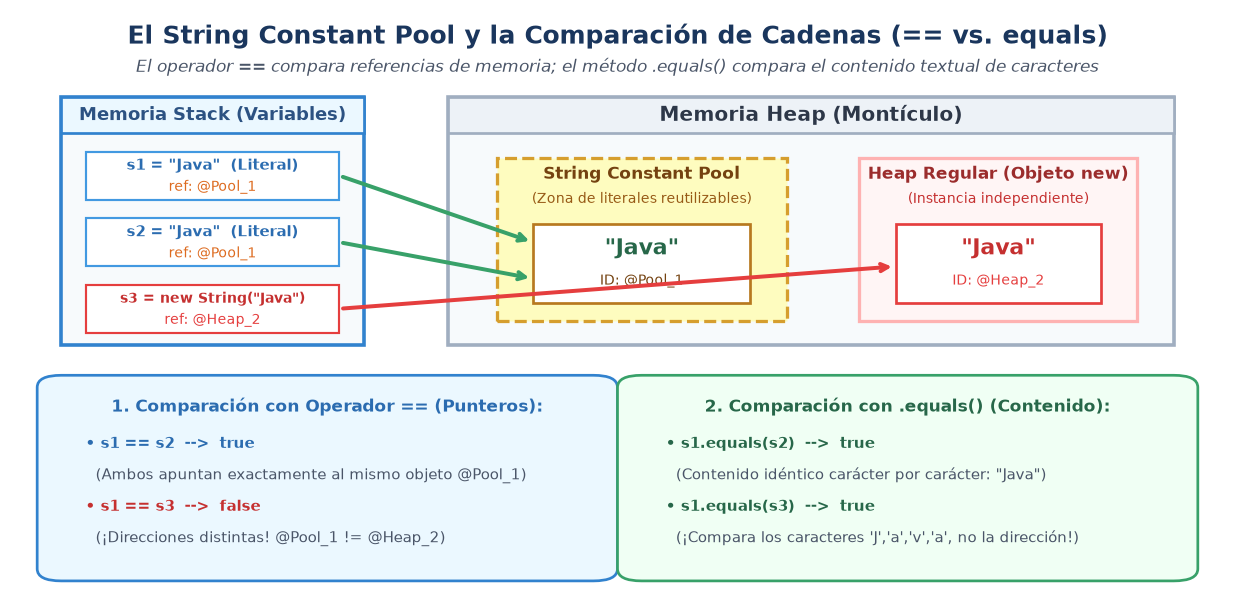
</div>

### 2.3 Comparación: El Operador `==` vs. el Método `.equals()`
Esta distinción en la arquitectura de memoria conduce a uno de los errores más comunes y críticos cometidos por programadores principiantes en Java:

* **El Operador `==` (Igualdad de Referencia):**
  Evalúa si dos variables apuntan a la **misma dirección de memoria física**. No inspecciona en absoluto qué caracteres contiene la cadena.
  * `s1 == s2`: Retorna `true` porque ambos apuntan al mismo objeto en el *String Pool*.
  * `s1 == s3`: Retorna **`false`**, a pesar de que ambos contienen las letras J-a-v-a, porque residen en direcciones de memoria Heap distintas.
* **El Método `.equals(Object obj)` (Igualdad de Estado/Contenido):**
  Heredado de la clase base `Object` y sobreescrito por `String`, recorre carácter por carácter verificando si ambas cadenas tienen exactamente la misma longitud y los mismos símbolos en las mismas posiciones.
  * `s1.equals(s3)`: Retorna **`true`**.

> **Regla de Oro en Java:**
> **JAMÁS** utilices el operador relacional `==` para comparar cadenas de texto en lógica de negocio. Utiliza siempre el método `.equals()` o `.equalsIgnoreCase()`.

### 2.4 El Método `.compareTo(String anotherString)` (Orden Lexicográfico)
Para determinar el orden alfabético relativo entre dos cadenas (por ejemplo, para ordenar listas de nombres o palabras en un diccionario), Java provee el método:

$$	ext{int cmp} = 	ext{s1.compareTo(s2)}$$

El valor entero retornado indica:
* `cmp < 0`: La cadena `s1` precede alfabéticamente a `s2` ($s_1 < s_2$).
* `cmp == 0`: Ambas cadenas son idénticas en contenido ($s_1 = s_2$).
* `cmp > 0`: La cadena `s1` sigue alfabéticamente a `s2` ($s_1 > s_2$).

*(Nota: En el orden lexicográfico de Java, las letras mayúsculas `'A'`–`'Z'` (códigos 65–90) preceden a las minúsculas `'a'`–`'z'` (códigos 97–122). Si deseas ignorar mayúsculas y minúsculas al comparar, utiliza `compareToIgnoreCase()`).*


### Demostración 1: Creación de Cadenas, String Pool y Comparación en Acción

Ejecuta el siguiente programa en Java para observar experimentalmente en consola cómo se comportan las referencias en el String Pool y por qué `==` difiere drásticamente de `.equals()`:


In [1]:
%%writefile DemostracionCreacionPool.java
public class DemostracionCreacionPool {
    public static void main(String[] args) {
        System.out.println("======================================================================");
        System.out.println("DEMOSTRACION 1: String Pool y Comparacion de Cadenas (== vs .equals)");
        System.out.println("======================================================================");

        // Creacion por literales (utilizan el String Constant Pool)
        String s1 = "Universidad";
        String s2 = "Universidad";

        // Creacion explicita mediante operador new (Heap independiente)
        String s3 = new String("Universidad");

        System.out.println("Cadenas creadas:");
        System.out.println("  s1 = \"Universidad\" (Literal)");
        System.out.println("  s2 = \"Universidad\" (Literal)");
        System.out.println("  s3 = new String(\"Universidad\") (Nuevo objeto en Heap)");
        System.out.println();

        // Comparacion con == (Identidad de Referencia de Memoria)
        System.out.println("1. Comparacion con operador == (¿Misma direccion de memoria?):");
        System.out.println("   s1 == s2 : " + (s1 == s2) + "  -> [TRUE: Ambos apuntan al mismo objeto en el Pool]");
        System.out.println("   s1 == s3 : " + (s1 == s3) + " -> [FALSE: s3 esta en una direccion distinta del Heap]");
        System.out.println();

        // Comparacion con .equals() (Contenido Textual)
        System.out.println("2. Comparacion con .equals() (¿Mismo contenido de caracteres?):");
        System.out.println("   s1.equals(s2) : " + s1.equals(s2) + " -> [TRUE: Contenido identico]");
        System.out.println("   s1.equals(s3) : " + s1.equals(s3) + " -> [TRUE: Contenido identico]");
        System.out.println();

        // Comparacion ignorando mayusculas / minusculas
        String sMayus = "UNIVERSIDAD";
        System.out.println("3. Sensibilidad a Mayusculas:");
        System.out.println("   s1.equals(\"UNIVERSIDAD\")           : " + s1.equals(sMayus));
        System.out.println("   s1.equalsIgnoreCase(\"UNIVERSIDAD\") : " + s1.equalsIgnoreCase(sMayus));
        System.out.println();

        // Ordenamiento Lexicografico con compareTo
        System.out.println("4. Comparacion Lexicografica con .compareTo():");
        String frutaA = "Manzana";
        String frutaB = "Pera";
        System.out.println("   \"Manzana\".compareTo(\"Pera\")    : " + frutaA.compareTo(frutaB) + " (Negativo -> 'M' va antes que 'P')");
        System.out.println("   \"Pera\".compareTo(\"Manzana\")    : " + frutaB.compareTo(frutaA) + " (Positivo -> 'P' va despues de 'M')");
        System.out.println("   \"Pera\".compareTo(\"Pera\")       : " + frutaB.compareTo("Pera") + " (Cero -> Son identicas)");
    }
}


Writing DemostracionCreacionPool.java


In [2]:
!javac -encoding UTF-8 DemostracionCreacionPool.java
!java DemostracionCreacionPool


[0.026s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.026s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
DEMOSTRACION 1: String Pool y Comparacion de Cadenas (== vs .equals)
Cadenas creadas:
  s1 = "Universidad" (Literal)
  s2 = "Universidad" (Literal)
  s3 = new String("Universidad") (Nuevo objeto en Heap)

1. Comparacion con operador == (¿Misma direccion de memoria?):
   s1 == s2 : true  -> [TRUE: Ambos apuntan al mismo objeto en el Pool]
  

## 3. La Inmutabilidad de las Cadenas: Fundamentos y Consecuencias en POO

Uno de los pilares de diseño más trascendentales de la clase `String` en Java es que sus instancias son **estrictamente inmutables** (*immutable objects*).

### 3.1 ¿Qué significa que un objeto sea inmutable?
Significa que una vez que un objeto `String` es instanciado y construido en la memoria Heap, **su estado interno (la secuencia de caracteres y su longitud) jamás puede ser alterado, modificado o reordenado**.

Ningún método de la clase `String` altera el objeto sobre el cual es invocado:
* Si llamas a `texto.toUpperCase()`, el objeto original `texto` permanece intacto en minúsculas. El método crea, rellena y retorna **un nuevo objeto `String`** independiente con las letras en mayúscula.
* Si ejecutas una concatenación como `texto = texto + " mundo";`, no estás agrandando el objeto original. La JVM reserva un nuevo objeto en el Heap con el texto combinado `"hola mundo"` y reasigna la variable de referencia `texto` para que apunte a ese nuevo objeto. El objeto anterior `"hola"` queda inalterado.

<div align="center">
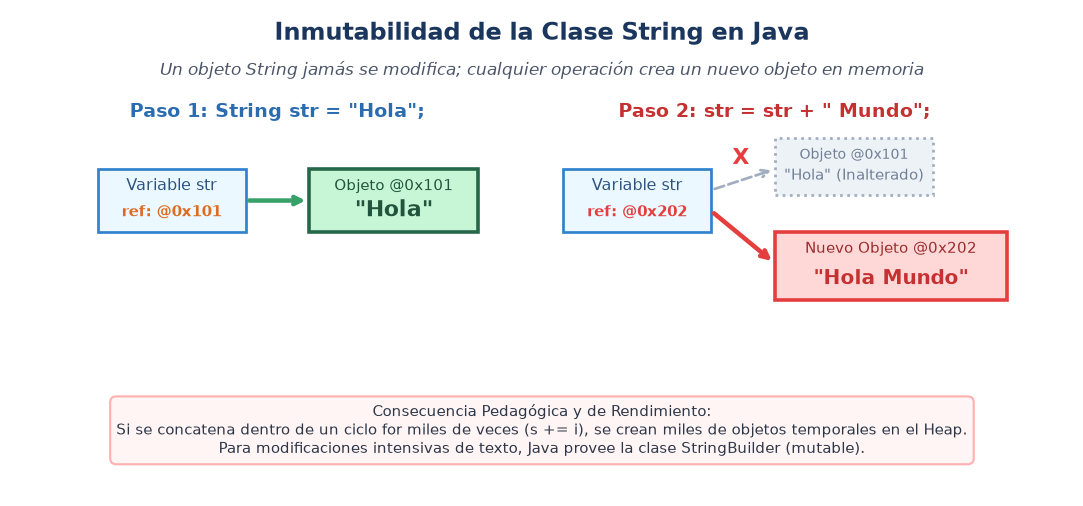
</div>

### 3.2 ¿Por qué los creadores de Java diseñaron `String` como inmutable?
1. **Seguridad y Criptografía:** Las cadenas se emplean para transportar parámetros confidenciales críticos: URLs de bases de datos, contraseñas de red, nombres de usuario y sockets de comunicación. Si fueran mutables, un hilo o método no autorizado podría alterar el destino de una conexión bancaria tras bambalinas.
2. **Sincronización y Seguridad en Hilos (Thread Safety):** Los objetos inmutables pueden ser compartidos libremente entre múltiples hilos de ejecución concurrentes sin necesidad de mecanismos de sincronización o bloqueos (*locks*), ya que ningún hilo puede corromper su estado.
3. **Optimización del String Constant Pool:** Si las cadenas fueran mutables, compartir la referencia `"Java"` entre `s1` y `s2` sería catastrófico: si `s1` cambiara una letra, ¡el valor de `s2` cambiaría involuntariamente! La inmutabilidad es la que hace posible la existencia del Pool.
4. **Almacenamiento en Caché del Código Hash (`hashCode`):** Como el contenido nunca cambia, el valor de dispersión numérico (*hash code*) de una cadena se calcula una sola vez y se almacena en caché. Esto hace que las cadenas sean las claves más rápidas y eficientes para tablas de dispersión (`HashMap`, `HashSet`).


### Demostración 2: Verificación de la Inmutabilidad en Java

En este ejemplo interactivo comprobaremos empíricamente que ningún método de transformación altera la cadena original si no se captura explícitamente el valor de retorno en una variable:


In [3]:
%%writefile DemostracionInmutabilidad.java
public class DemostracionInmutabilidad {
    public static void main(String[] args) {
        System.out.println("======================================================================");
        System.out.println("DEMOSTRACION 2: Comprobando la Inmutabilidad de java.lang.String");
        System.out.println("======================================================================");

        String fraseOriginal = "ingenieria de sistemas";
        System.out.println("1. Frase original: \"" + fraseOriginal + "\"");

        // Intentamos transformarla a mayusculas sin reasignar la variable
        fraseOriginal.toUpperCase();

        System.out.println("2. Despues de invocar fraseOriginal.toUpperCase() (SIN reasignar):");
        System.out.println("   fraseOriginal sigue siendo: \"" + fraseOriginal + "\"");
        System.out.println("   -> ¡El objeto original no cambio en absoluto!");
        System.out.println();

        // Para capturar la transformacion, debemos asignar la referencia retornada
        String fraseMayus = fraseOriginal.toUpperCase();
        System.out.println("3. Capturando el nuevo objeto retornado:");
        System.out.println("   fraseMayus: \"" + fraseMayus + "\"");
        System.out.println("   fraseOriginal: \"" + fraseOriginal + "\" (Sigue intacta)");
        System.out.println();

        // Concatenacion sucesiva
        String s = "A";
        String sInicial = s;
        s = s + "B"; // s ahora apunta a un nuevo objeto "AB"
        s = s + "C"; // s ahora apunta a otro nuevo objeto "ABC"

        System.out.println("4. Rastreo de Referencias tras Concatenacion:");
        System.out.println("   Valor final de s: " + s);
        System.out.println("   ¿s apunta al mismo objeto original sInicial?: " + (s == sInicial) + " (FALSE)");
    }
}


Writing DemostracionInmutabilidad.java


In [4]:
!javac -encoding UTF-8 DemostracionInmutabilidad.java
!java DemostracionInmutabilidad


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
DEMOSTRACION 2: Comprobando la Inmutabilidad de java.lang.String
1. Frase original: "ingenieria de sistemas"
2. Despues de invocar fraseOriginal.toUpperCase() (SIN reasignar):
   fraseOriginal sigue siendo: "ingenieria de sistemas"
   -> ¡El objeto original no cambio en absoluto!

3. Capturando el nuevo objeto retornado:
   fraseMayus: "ING

## 4. Métodos Esenciales de la Clase `String`

La API de `java.lang.String` ofrece un repertorio completo de métodos para inspeccionar, consultar, transformar y diseccionar texto.

<div align="center">
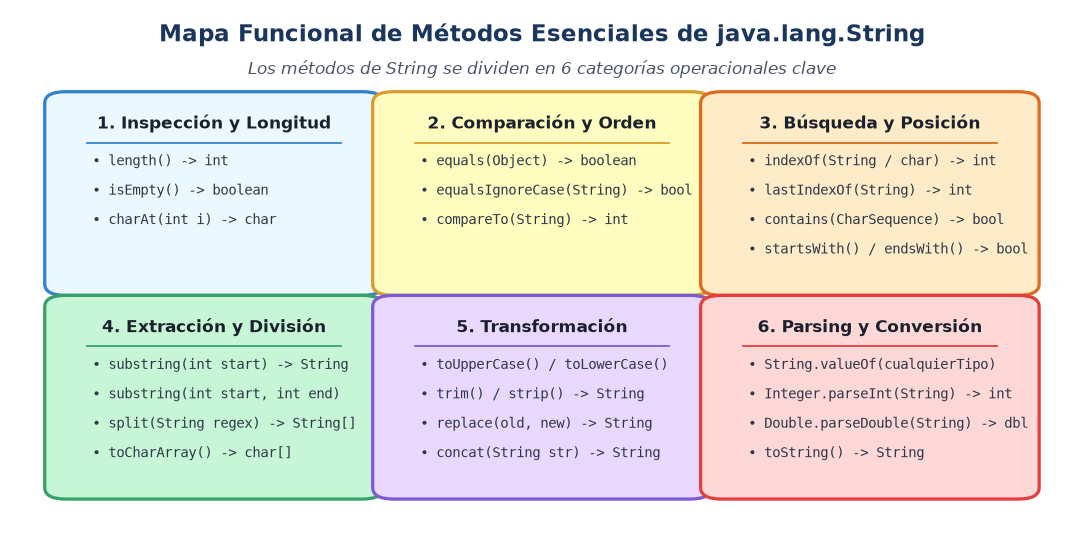
</div>

---

### 4.1 Métodos de Inspección y Tamaño
* **`int length()`:** Retorna la cantidad total de caracteres presentes en la cadena.
  * `"Hola".length()` retorna `4`.
  * `"".length()` retorna `0`.
* **`boolean isEmpty()`:** Retorna `true` si `length() == 0`.
* **`char charAt(int index)`:** Retorna el carácter ubicado en el índice especificado (en base 0).
  * Si el índice es menor que 0 o mayor o igual a `length()`, Java lanza la excepción en tiempo de ejecución **`StringIndexOutOfBoundsException`**.

---

### 4.2 Métodos de Búsqueda y Posición
* **`int indexOf(String str)`:** Retorna el índice de la primera ocurrencia de la subcadena `str`. Si no la encuentra, retorna **`-1`**.
* **`int indexOf(String str, int fromIndex)`:** Inicia la búsqueda a partir del índice `fromIndex`.
* **`int lastIndexOf(String str)`:** Retorna el índice de la última ocurrencia de la subcadena.
* **`boolean contains(CharSequence s)`:** Retorna `true` si la secuencia `s` se encuentra contenida en cualquier parte de la cadena.
* **`boolean startsWith(String prefix)`:** Verifica si la cadena inicia con el prefijo dado.
* **`boolean endsWith(String suffix)`:** Verifica si la cadena finaliza con el sufijo dado.

---

### 4.3 Métodos de Extracción y Recorte: El Funcionamiento de `substring`
La extracción de fragmentos de texto en Java se realiza mediante el método `substring`. Es crítico comprender su regla de indexación:

<div align="center">
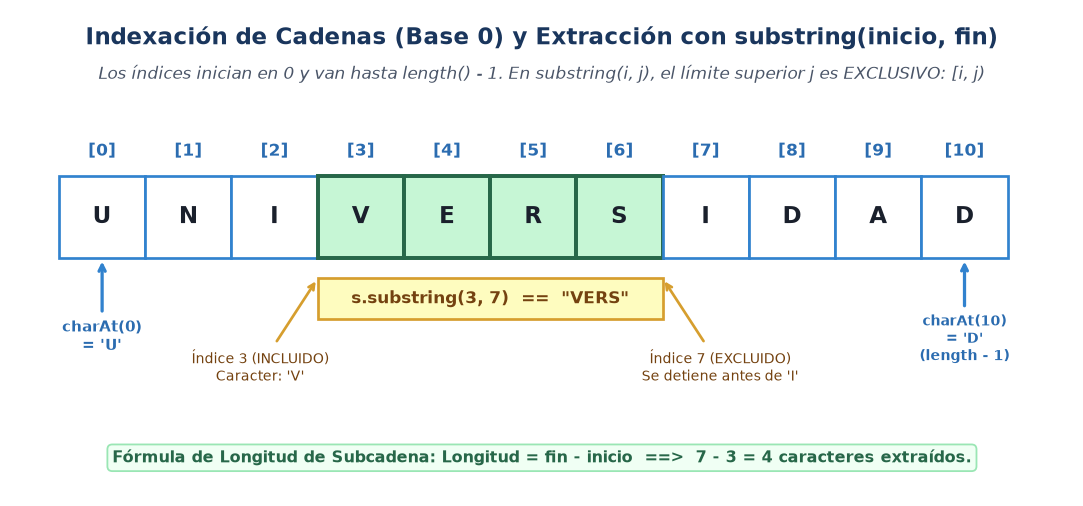
</div>

* **`String substring(int beginIndex)`:** Extrae desde `beginIndex` (inclusive) hasta el final de la cadena.
* **`String substring(int beginIndex, int endIndex)`:** Extrae los caracteres en el intervalo semiabierto $[\text{beginIndex}, \text{endIndex})$.
  * El carácter en la posición `beginIndex` **está incluido**.
  * El carácter en la posición `endIndex` **está excluido** (la extracción se detiene en `endIndex - 1`).
  * **Fórmula de longitud resultante:** $\text{Longitud} = \text{endIndex} - \text{beginIndex}$.
* **`String trim()`:** Elimina los espacios en blanco, tabulaciones y saltos de línea al inicio y al final de la cadena.

---

### 4.4 Métodos de Transformación y Reemplazo
* **`String toLowerCase()`:** Retorna una nueva cadena con todas las letras convertidas a minúsculas.
* **`String toUpperCase()`:** Retorna una nueva cadena con todas las letras en mayúsculas.
* **`String replace(char oldChar, char newChar)`:** Retorna una nueva cadena donde todas las apariciones de `oldChar` han sido sustituidas por `newChar`.
* **`String replace(CharSequence target, CharSequence replacement)`:** Sustituye ocurrencias exactas de secuencias de texto.

---

### 4.5 División de Texto (`split`) y Conversión a Caracteres
* **`String[] split(String regex)`:** Divide la cadena en múltiples fragmentos utilizando el delimitador indicado (un espacio `" "`, una coma `","`, un punto y coma `";"` o una barra `"&"`), retornando un arreglo de cadenas (`String[]`).
* **`char[] toCharArray()`:** Retorna una copia de los caracteres internos de la cadena en forma de un arreglo de primitivos `char[]`.


### Demostración 3: Inspección, Búsqueda y Extracción en Acción

Ejecuta el siguiente programa para observar el funcionamiento de los métodos de búsqueda y extracción sobre un texto de prueba:


In [5]:
%%writefile DemostracionBusquedaExtraccion.java
public class DemostracionBusquedaExtraccion {
    public static void main(String[] args) {
        System.out.println("======================================================================");
        System.out.println("DEMOSTRACION 3: Inspeccion, Busqueda y Extraccion con String");
        System.out.println("======================================================================");

        String texto = "Universidad Nacional de Colombia";
        System.out.println("Texto de prueba: \"" + texto + "\"");
        System.out.println("Longitud total (length): " + texto.length() + " caracteres");
        System.out.println();

        // 1. Acceso a caracteres
        System.out.println("1. Acceso por indice con charAt():");
        System.out.println("   Primer caracter  (indice 0)            : '" + texto.charAt(0) + "'");
        System.out.println("   Ultimo caracter  (indice length - 1)   : '" + texto.charAt(texto.length() - 1) + "'");
        System.out.println("   Caracter central (indice 12)           : '" + texto.charAt(12) + "'");
        System.out.println();

        // 2. Busqueda de posiciones
        System.out.println("2. Busqueda con indexOf() y contains():");
        System.out.println("   Posicion de \"Nacional\": " + texto.indexOf("Nacional"));
        System.out.println("   Posicion de la letra 'a' (primera): " + texto.indexOf('a'));
        System.out.println("   Posicion de la letra 'a' (ultima) : " + texto.lastIndexOf('a'));
        System.out.println("   ¿Contiene \"Colombia\"?: " + texto.contains("Colombia"));
        System.out.println("   ¿Contiene \"Antioquia\"?: " + texto.contains("Antioquia") + " (retorna -1 con indexOf: " + texto.indexOf("Antioquia") + ")");
        System.out.println("   ¿Comienza con \"Univ\"?: " + texto.startsWith("Univ"));
        System.out.println("   ¿Termina con \"bia\"?: " + texto.endsWith("bia"));
        System.out.println();

        // 3. Extraccion con substring
        System.out.println("3. Extraccion con substring(inicio, fin):");
        String p1 = texto.substring(0, 11); // [0, 11) -> "Universidad"
        String p2 = texto.substring(12, 20); // [12, 20) -> "Nacional"
        String p3 = texto.substring(24);     // [24, fin) -> "Colombia"

        System.out.println("   substring(0, 11)  -> \"" + p1 + "\" (Longitud: " + p1.length() + ")");
        System.out.println("   substring(12, 20) -> \"" + p2 + "\" (Longitud: " + p2.length() + ")");
        System.out.println("   substring(24)     -> \"" + p3 + "\" (Longitud: " + p3.length() + ")");
    }
}


Writing DemostracionBusquedaExtraccion.java


In [6]:
!javac -encoding UTF-8 DemostracionBusquedaExtraccion.java
!java DemostracionBusquedaExtraccion


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
DEMOSTRACION 3: Inspeccion, Busqueda y Extraccion con String
Texto de prueba: "Universidad Nacional de Colombia"
Longitud total (length): 32 caracteres

1. Acceso por indice con charAt():
   Primer caracter  (indice 0)            : 'U'
   Ultimo caracter  (indice length - 1)   : 'a'
   Caracter central (indice 12)           : 'N'

2. Busque

## 5. Transformación de Cadenas, División (`split`) y Conversión de Tipos (Parsing)

En aplicaciones de entrada y salida de datos (como formularios web, lectura de archivos CSV o ingreso por teclado), los valores ingresan siempre como texto plano (`String`), incluso cuando representan números enteros o flotantes.

### 5.1 Conversión de Texto a Números: Clases Envoltorio (*Wrapper Classes*)
Para transformar cadenas a valores numéricos primitivos con los que se puedan realizar operaciones matemáticas, se emplean los métodos estáticos de parseo de las clases envoltorio:

* **De `String` a `int`:**
  ```java
  String strEdad = "24";
  int edad = Integer.parseInt(strEdad);
  ```
* **De `String` a `double`:**
  ```java
  String strPrecio = "15490.50";
  double precio = Double.parseDouble(strPrecio);
  ```

*(Nota técnica: Si la cadena contiene caracteres no numéricos o espacios que impidan su conversión matemática, Java lanzará la excepción `NumberFormatException`).*

### 5.2 Conversión de Tipos Primitivos a `String`
Para convertir cualquier tipo primitivo u objeto a su representación textual, existen dos alternativas idiomáticas:
1. **Método formal:** `String.valueOf(valor)`:
   ```java
   String s = String.valueOf(3.14159);
   ```
2. **Concatenación con cadena vacía:**
   ```java
   String s = "" + 3.14159;
   ```

### 5.3 División de Registros con `split(delimitador)`
El método `split` descompone una cadena estructurada en fragmentos basándose en un patrón separador. Es la base para procesar líneas de texto con formatos alfanuméricos como `Nombre&Edad&Salario`:

```java
String linea = "Carlos Andres&28&4500.0";
String[] partes = linea.split("&");
String nombre = partes[0];
int edad = Integer.parseInt(partes[1]);
double salario = Double.parseDouble(partes[2]);
```


### Demostración 4: Transformación, Limpieza de Texto y Parsing Numérico

El siguiente programa ilustra la limpieza de texto con `trim()`, transformaciones mayúsculas/minúsculas, reemplazo de caracteres y procesamiento de una línea de datos tabulares delimitados:


In [7]:
%%writefile DemostracionTransformacionParsing.java
public class DemostracionTransformacionParsing {
    public static void main(String[] args) {
        System.out.println("======================================================================");
        System.out.println("DEMOSTRACION 4: Transformacion, Limpieza y Parsing Numerico");
        System.out.println("======================================================================");

        // 1. Limpieza de espacios con trim()
        String entradaSucia = "   Hola, Mundo con Espacios!   \n\t  ";
        System.out.println("1. Limpieza de texto:");
        System.out.println("   Texto sin procesar : ['" + entradaSucia + "']");
        String entradaLimpia = entradaSucia.trim();
        System.out.println("   Despues de trim()  : ['" + entradaLimpia + "']");
        System.out.println();

        // 2. Reemplazo de caracteres
        System.out.println("2. Reemplazo con replace():");
        String codigo = "2026-SEMESTRE-2";
        String codigoModificado = codigo.replace('-', '/');
        System.out.println("   Original: " + codigo);
        System.out.println("   Modificado: " + codigoModificado);
        System.out.println();

        // 3. Procesamiento de registros con split() y parsing numerico
        System.out.println("3. Procesamiento y Parsing de Registros:");
        String registro = "Camila Restrepo;19;4.75;Activo";
        System.out.println("   Registro recibido: \"" + registro + "\"");

        String[] campos = registro.split(";");
        String nombre = campos[0];
        int edad = Integer.parseInt(campos[1]);
        double promedio = Double.parseDouble(campos[2]);
        boolean activo = Boolean.parseBoolean(campos[3]);

        System.out.println("   Datos estructurados extraidos:");
        System.out.println("     - Nombre   : " + nombre.toUpperCase());
        System.out.println("     - Edad     : " + edad + " años");
        System.out.println("     - Promedio : " + promedio);
        System.out.println("     - ¿Activo? : " + activo);
        System.out.println("     - ¿Promedio Meritorio (> 4.5)?: " + (promedio >= 4.5));
    }
}


Writing DemostracionTransformacionParsing.java


In [8]:
!javac -encoding UTF-8 DemostracionTransformacionParsing.java
!java DemostracionTransformacionParsing


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
DEMOSTRACION 4: Transformacion, Limpieza y Parsing Numerico
1. Limpieza de texto:
   Texto sin procesar : ['   Hola, Mundo con Espacios!   
	  ']
   Despues de trim()  : ['Hola, Mundo con Espacios!']

2. Reemplazo con replace():
   Original: 2026-SEMESTRE-2
   Modificado: 2026/SEMESTRE/2

3. Procesamiento y Parsing de Registros:
   Registro

## 6. Lectura de Cadenas por Consola: `Scanner.next()` vs. `Scanner.nextLine()`

Al leer texto ingresado por el usuario a través de `java.util.Scanner`, es fundamental distinguir entre la lectura de una sola palabra y la lectura de una línea completa:

* **`scanner.next()`:** Lee la siguiente palabra o *token*, delimitado por espacios en blanco, tabulaciones o saltos de línea. Se detiene en cuanto encuentra el primer espacio.
* **`scanner.nextLine()`:** Lee la línea completa de texto desde la posición actual hasta encontrar el salto de línea `\n` (cuando el usuario presiona Enter), consumiendo dicho salto y retornando toda la frase.

```java
Scanner sc = new Scanner(System.in);
System.out.print("Ingrese su nombre completo: ");
String nombreCompleto = sc.nextLine(); // Lee "Ana Maria Gomez" completo
```

---

## 7. Buenas Prácticas de Rendimiento y la Clase `StringBuilder`

Como comprobamos en la sección de inmutabilidad, concatenar texto con el operador `+` dentro de un ciclo que se ejecuta miles de veces crea una gran cantidad de objetos intermedios efímeros en el Heap, obligando al recolector de basura (*Garbage Collector*) a trabajar intensivamente:

```java
// ANTIPATRÓN DE RENDIMIENTO (Evitar para miles de repeticiones):
String s = "";
for (int i = 0; i < 10000; i++) {
    s += i; // Crea 10,000 objetos temporales en Heap
}
```

Para operaciones de modificación y ensamblado intensivo de cadenas, Java proporciona la clase **`StringBuilder`**, la cual representa una secuencia **mutable** de caracteres sobre un único bloque de memoria ajustable:

```java
// PATRÓN RECOMENDADO:
StringBuilder sb = new StringBuilder();
for (int i = 0; i < 10000; i++) {
    sb.append(i); // Modifica el arreglo interno in situ sin crear objetos extra
}
String resultado = sb.toString();
```

*(Para concatenaciones simples y cortas como `"Hola, " + nombre + "!"`, el operador `+` es perfectamente válido y legible, pues el compilador de Java lo optimiza automáticamente).*


## 8. Ejercicios Prácticos


### Ejercicio 1: Validador y Normalizador de Nombres y Correos (`NormalizadorTexto.java`)

**Objetivo:** Desarrollar funciones para limpiar y normalizar entradas de texto de usuarios, eliminando espacios innecesarios, estandarizando mayúsculas/minúsculas y validando estructuras básicas de correo electrónico.

**Instrucciones:**
1. Complete el método `normalizarNombre(String nombre)`: Debe eliminar espacios en blanco al inicio y al final con `trim()`, y convertir la primera letra a mayúscula y el resto a minúsculas (ejemplo: `"  jUAn  "` $\rightarrow$ `"Juan"`).
2. Complete el método `validarCorreoInstitucional(String correo)`: Debe retornar `true` si el correo contiene el carácter `'@'`, termina exactamente con el dominio `"@unal.edu.co"` y no contiene espacios.
3. Ejecute las pruebas unitarias incorporadas en el método `main`.


In [ ]:
%%writefile NormalizadorTexto.java
public class NormalizadorTexto {

    // TODO 1: Implemente la normalizacion de un nombre (Primera mayuscula, resto minusculas, sin espacios)
    public static String normalizarNombre(String nombre) {
        if (nombre == null || nombre.trim().isEmpty()) {
            return "";
        }
        // --- ESCRIBA SU CODIGO AQUI ---
        String limpio = nombre.trim();
        String primeraLetra = limpio.substring(0, 1).toUpperCase();
        String resto = limpio.substring(1).toLowerCase();
        return primeraLetra + resto;
        // ------------------------------
    }

    // TODO 2: Valide que sea un correo valido terminado en @unal.edu.co
    public static boolean validarCorreoInstitucional(String correo) {
        if (correo == null) return false;
        // --- ESCRIBA SU CODIGO AQUI ---
        String c = correo.trim().toLowerCase();
        return c.contains("@") && c.endsWith("@unal.edu.co") && !c.contains(" ");
        // ------------------------------
    }

    public static void main(String[] args) {
        System.out.println("=== TEST EJERCICIO 1: NORMALIZADOR DE TEXTO ===");

        // Pruebas de normalizacion
        String t1 = normalizarNombre("   cARLOS  ");
        String t2 = normalizarNombre("elena");
        boolean ok1 = t1.equals("Carlos") && t2.equals("Elena");
        System.out.println("Prueba 1 (normalizarNombre): " + (ok1 ? "PASO [OK]" : "FALLO [ERROR]"));
        System.out.println("  '   cARLOS  ' -> \"" + t1 + "\"");

        // Pruebas de correo
        boolean c1 = validarCorreoInstitucional("daherreraa@unal.edu.co");
        boolean c2 = validarCorreoInstitucional("estudiante@gmail.com");
        boolean c3 = validarCorreoInstitucional("invalido @unal.edu.co");
        boolean ok2 = c1 && !c2 && !c3;
        System.out.println("Prueba 2 (validarCorreo)  : " + (ok2 ? "PASO [OK]" : "FALLO [ERROR]"));
    }
}


In [ ]:
!javac -encoding UTF-8 NormalizadorTexto.java
!java NormalizadorTexto


### Ejercicio 2: Analizador Estadístico de Vocales, Consonantes y Dígitos (`AnalizadorTexto.java`)

**Objetivo:** Desarrollar un componente que analice una cadena de texto arbitraria y clasifique sus caracteres, contando el número de vocales, consonantes, dígitos numéricos y espacios en blanco.

**Instrucciones:**
1. Recorra la cadena carácter por carácter utilizando un bucle `for` y el método `charAt(i)`.
2. Emplee los métodos auxiliares `Character.isLetter(c)` y `Character.isDigit(c)` (o comparaciones por rango numérico Unicode) para discriminar entre letras y números.
3. Considere tanto mayúsculas como minúsculas al identificar vocales (`'a', 'e', 'i', 'o', 'u'`).


In [ ]:
%%writefile AnalizadorTexto.java
public class AnalizadorTexto {

    public static class MetricasTexto {
        public int vocales = 0;
        public int consonantes = 0;
        public int digitos = 0;
        public int espacios = 0;
    }

    // TODO: Analice el texto y compute las metricas solicitadas
    public static MetricasTexto analizar(String texto) {
        MetricasTexto m = new MetricasTexto();
        if (texto == null) return m;

        // --- ESCRIBA SU CODIGO AQUI ---
        String minus = texto.toLowerCase();
        for (int i = 0; i < minus.length(); i++) {
            char c = minus.charAt(i);
            if (c == 'a' || c == 'e' || c == 'i' || c == 'o' || c == 'u' ||
                c == 'á' || c == 'é' || c == 'í' || c == 'ó' || c == 'ú') {
                m.vocales++;
            } else if (Character.isLetter(c)) {
                m.consonantes++;
            } else if (Character.isDigit(c)) {
                m.digitos++;
            } else if (Character.isWhitespace(c)) {
                m.espacios++;
            }
        }
        // ------------------------------
        return m;
    }

    public static void main(String[] args) {
        System.out.println("=== TEST EJERCICIO 2: ANALIZADOR DE TEXTO ===");

        String entrada = "Java 17 en la UNAL 2026";
        MetricasTexto r = analizar(entrada);

        System.out.println("Texto analizado: \"" + entrada + "\"");
        System.out.println("  Vocales     : " + r.vocales     + " (Esperado: 6)");
        System.out.println("  Consonantes : " + r.consonantes + " (Esperado: 6)");
        System.out.println("  Digitos     : " + r.digitos     + " (Esperado: 6)");
        System.out.println("  Espacios    : " + r.espacios    + " (Esperado: 4)");

        boolean ok = (r.vocales == 6 && r.consonantes == 6 && r.digitos == 6 && r.espacios == 4);
        System.out.println("Resultado de la prueba: " + (ok ? "PASO [OK]" : "FALLO [ERROR]"));
    }
}


In [ ]:
!javac -encoding UTF-8 AnalizadorTexto.java
!java AnalizadorTexto


### Ejercicio 3: Inversor de Texto y Verificador de Palíndromos (`VerificadorPalindromo.java`)

**Objetivo:** Implementar un algoritmo que invierta una cadena de caracteres y determine si una frase es un **palíndromo** (se lee igual al derecho y al revés, ignorando espacios, signos de puntuación y diferencias entre mayúsculas y minúsculas).

**Instrucciones:**
1. Implemente el método `invertir(String s)` que retorne una nueva cadena con los caracteres en orden inverso.
2. Implemente el método `esPalindromo(String frase)`:
   - Limpie la frase convirtiéndola a minúsculas y removiendo espacios y signos no alfabéticos.
   - Compare la cadena limpia con su versión invertida usando `.equals()`.
   - Ejemplos válidos: `"radar"`, `"reconocer"`, `"anita lava la tina"`, `"robas ese sabor"`.


In [ ]:
%%writefile VerificadorPalindromo.java
public class VerificadorPalindromo {

    // TODO 1: Retorna la cadena invertida caracter por caracter
    public static String invertir(String s) {
        if (s == null) return "";
        // --- ESCRIBA SU CODIGO AQUI ---
        StringBuilder sb = new StringBuilder();
        for (int i = s.length() - 1; i >= 0; i--) {
            sb.append(s.charAt(i));
        }
        return sb.toString();
        // ------------------------------
    }

    // TODO 2: Verifica si la frase es un palindromo (ignorando espacios y mayusculas)
    public static boolean esPalindromo(String frase) {
        if (frase == null) return false;
        // --- ESCRIBA SU CODIGO AQUI ---
        // 1. Filtrar solo caracteres alfabeticos y pasar a minusculas
        StringBuilder limpio = new StringBuilder();
        String minus = frase.toLowerCase();
        for (int i = 0; i < minus.length(); i++) {
            char c = minus.charAt(i);
            if (Character.isLetterOrDigit(c)) {
                limpio.append(c);
            }
        }
        String originalLimpia = limpio.toString();
        String invertidaLimpia = invertir(originalLimpia);
        return originalLimpia.equals(invertidaLimpia);
        // ------------------------------
    }

    public static void main(String[] args) {
        System.out.println("=== TEST EJERCICIO 3: INVERSOR Y PALINDROMOS ===");

        // Test Invertir
        String inv = invertir("UNAL");
        System.out.println("Invertir \"UNAL\": \"" + inv + "\" (Esperado: \"LANU\")");
        boolean okInv = inv.equals("LANU");

        // Test Palindromos
        boolean p1 = esPalindromo("reconocer");
        boolean p2 = esPalindromo("anita lava la tina");
        boolean p3 = esPalindromo("robas ese sabor");
        boolean p4 = esPalindromo("programacion en java");

        System.out.println("¿'reconocer' es palindromo?          : " + p1 + " (Esperado: true)");
        System.out.println("¿'anita lava la tina' es palindromo? : " + p2 + " (Esperado: true)");
        System.out.println("¿'robas ese sabor' es palindromo?    : " + p3 + " (Esperado: true)");
        System.out.println("¿'programacion en java' es palindromo?: " + p4 + " (Esperado: false)");

        boolean okPal = p1 && p2 && p3 && !p4;
        System.out.println("Resultado de la prueba: " + (okInv && okPal ? "PASO [OK]" : "FALLO [ERROR]"));
    }
}


In [ ]:
!javac -encoding UTF-8 VerificadorPalindromo.java
!java VerificadorPalindromo


### Ejercicio 4: Extractor y Parser de Registros Tabulares (`ParserRegistros.java`)

**Objetivo:** Modelar un sistema orientado a objetos para leer y procesar líneas de texto con formato delimitado alfanumérico (`CodigoEstudiante#Nombre#Nota1,Nota2,Nota3`), instanciando objetos del dominio `Estudiante` y calculando su promedio numérico ponderado.

**Instrucciones:**
1. Complete la clase `Estudiante` con los atributos `codigo`, `nombre` y `promedio`.
2. En `parsearEstudiante(String linea)`:
   - Divida la línea con `linea.split("#")`.
   - Extraiga el código y el nombre.
   - Divida el tercer campo de notas separadas por coma `notas.split(",")`.
   - Convierta cada nota a `double` con `Double.parseDouble()` y calcule el promedio aritmético.


In [ ]:
%%writefile ParserRegistros.java
public class ParserRegistros {

    public static class Estudiante {
        private String codigo;
        private String nombre;
        private double promedio;

        public Estudiante(String codigo, String nombre, double promedio) {
            this.codigo = codigo;
            this.nombre = nombre;
            this.promedio = promedio;
        }

        public String getCodigo() { return codigo; }
        public String getNombre() { return nombre; }
        public double getPromedio() { return promedio; }

        @Override
        public String toString() {
            return String.format("[%s] %s - Promedio: %.2f", codigo, nombre, promedio);
        }
    }

    // TODO: Parsee la linea con formato "Codigo#Nombre#Nota1,Nota2,Nota3"
    public static Estudiante parsearEstudiante(String linea) {
        if (linea == null || linea.trim().isEmpty()) return null;

        // --- ESCRIBA SU CODIGO AQUI ---
        String[] partes = linea.split("#");
        String codigo = partes[0].trim();
        String nombre = partes[1].trim();

        String[] notasStr = partes[2].split(",");
        double suma = 0;
        for (String n : notasStr) {
            suma += Double.parseDouble(n.trim());
        }
        double prom = suma / notasStr.length;

        return new Estudiante(codigo, nombre, prom);
        // ------------------------------
    }

    public static void main(String[] args) {
        System.out.println("=== TEST EJERCICIO 4: PARSER DE REGISTROS DE ESTUDIANTES ===");

        String registro1 = "2026101#Laura Morales#4.5,4.0,5.0";
        String registro2 = "2026102#Santiago Gomez#3.5,3.8,4.1";

        Estudiante e1 = parsearEstudiante(registro1);
        Estudiante e2 = parsearEstudiante(registro2);

        System.out.println("Estudiante 1 procesado: " + e1);
        System.out.println("Estudiante 2 procesado: " + e2);

        boolean ok1 = e1 != null && e1.getCodigo().equals("2026101") && Math.abs(e1.getPromedio() - 4.5) < 0.01;
        boolean ok2 = e2 != null && e2.getCodigo().equals("2026102") && Math.abs(e2.getPromedio() - 3.8) < 0.01;

        System.out.println("Resultado de la prueba: " + (ok1 && ok2 ? "PASO [OK]" : "FALLO [ERROR]"));
    }
}


In [ ]:
!javac -encoding UTF-8 ParserRegistros.java
!java ParserRegistros


### Ejercicio 5: Cifrador y Descifrador César Orientado a Objetos (`CifradorCesar.java`)

**Objetivo:** Diseñar una clase `CifradorCesar` que encapsule una clave de desplazamiento entero $k$ y provea métodos de instancia para cifrar y descifrar mensajes de texto, aplicando aritmética modular sobre el alfabeto inglés (`'A'`–`'Z'` y `'a'`–`'z'`).

**Fundamento Teórico:**
El cifrado César reemplaza cada letra por la que se encuentra $k$ posiciones más adelante en el alfabeto:
$$C = (P + k) \pmod{26}$$
Donde $P$ es la posición de la letra en el alfabeto (0 a 25) y $C$ es la letra cifrada. Los caracteres no alfabéticos (espacios, números, puntuación) se mantienen inalterados.

**Instrucciones:**
1. Complete el constructor `CifradorCesar(int desplazamiento)` normalizando el desplazamiento con módulo 26.
2. Complete el método `cifrar(String mensaje)` iterando sobre los caracteres y aplicando el desplazamiento alfabético adecuado preservando mayúsculas y minúsculas.
3. Complete el método `descifrar(String mensajeCifrado)` aplicando el desplazamiento inverso.


In [ ]:
%%writefile CifradorCesar.java
public class CifradorCesar {
    private int desplazamiento;

    public CifradorCesar(int desplazamiento) {
        // Normalizar a un rango de 0 a 25
        this.desplazamiento = ((desplazamiento % 26) + 26) % 26;
    }

    // TODO 1: Cifra el mensaje aplicando el desplazamiento cesar
    public String cifrar(String mensaje) {
        if (mensaje == null) return null;
        StringBuilder resultado = new StringBuilder();

        // --- ESCRIBA SU CODIGO AQUI ---
        for (int i = 0; i < mensaje.length(); i++) {
            char c = mensaje.charAt(i);
            if (c >= 'A' && c <= 'Z') {
                char nuevo = (char) ('A' + (c - 'A' + desplazamiento) % 26);
                resultado.append(nuevo);
            } else if (c >= 'a' && c <= 'z') {
                char nuevo = (char) ('a' + (c - 'a' + desplazamiento) % 26);
                resultado.append(nuevo);
            } else {
                resultado.append(c); // Espacios y signos quedan inalterados
            }
        }
        // ------------------------------
        return resultado.toString();
    }

    // TODO 2: Descifra el mensaje aplicando el desplazamiento inverso
    public String descifrar(String mensajeCifrado) {
        if (mensajeCifrado == null) return null;
        // El descifrado equivale a cifrar con (26 - desplazamiento)
        CifradorCesar descifrador = new CifradorCesar(26 - this.desplazamiento);
        return descifrador.cifrar(mensajeCifrado);
    }

    public static void main(String[] args) {
        System.out.println("=== TEST EJERCICIO 5: CIFRADOR CESAR ORIENTADO A OBJETOS ===");

        CifradorCesar cesar = new CifradorCesar(3);
        String textoOriginal = "Hola Mundo, Java 2026!";
        String textoCifrado = cesar.cifrar(textoOriginal);
        String textoDescifrado = cesar.descifrar(textoCifrado);

        System.out.println("Mensaje Original    : \"" + textoOriginal + "\"");
        System.out.println("Mensaje Cifrado (+3): \"" + textoCifrado + "\"");
        System.out.println("Mensaje Descifrado  : \"" + textoDescifrado + "\"");

        boolean ok = textoOriginal.equals(textoDescifrado) && !textoOriginal.equals(textoCifrado);
        System.out.println("Resultado de la prueba: " + (ok ? "PASO [OK]" : "FALLO [ERROR]"));
    }
}


In [ ]:
!javac -encoding UTF-8 CifradorCesar.java
!java CifradorCesar


## 9. Bibliografía y Referencias

1. **Streib, J. T., & Soma, T.** (2014). *Guide to Java: A Concise Introduction to Programming*. Chapter 6: *Strings*. Springer-Verlag London.
2. **Barnes, D. J., & Kölling, M.** (2017). *Programación orientada a objetos con Java usando BlueJ*. 6.ª edición. Capítulo 3: *Interacción de objetos*. Pearson Educación.
3. **Deitel, P., & Deitel, H.** (2018). *Java: How to Program* (Early Objects). 11th Edition. Chapter 14: *Strings, Characters and Regular Expressions*. Pearson.
4. **Oracle Corporation.** *Java Platform, Standard Edition & Java Development Kit Version 17 API Specification: Class String*. [https://docs.oracle.com/en/java/javase/17/docs/api/java.base/java/lang/String.html](https://docs.oracle.com/en/java/javase/17/docs/api/java.base/java/lang/String.html).
5. **Bloch, J.** (2018). *Effective Java*. 3rd Edition. Item 63: *Beware the performance of string concatenation*. Addison-Wesley Professional.
